In [ ]:
import pandas as pd
import numpy as np

In [ ]:
df_train = pd.read_csv("../data/train.csv")  # note that all next columns are present , it has been done that way
df_test = pd.read_csv("../data/test.csv")

## Split into train/validation folds based on date

In [14]:


dev = df_train.copy()

dev["date"] = pd.to_datetime(dev["date"])
dev = dev.sort_values(["id", "date"])


dev["sleep_hours"] = dev["sleep_duration"] / 3_600_000

folds = []

for k in range(3):

    fit_idx = []
    val_idx = []

    for pid, group in dev.groupby("id"):
        n = len(group)

        # skip that participant if  less than 10 observation 
        if n < 10:
            continue

        # Boundaries at 40%, 60%, 80%, 100%
        cuts = [
            int(np.floor(n * fraction))
            for fraction in [0.4, 0.6, 0.8, 1.0]
        ]

        train_end = cuts[k]
        val_end = cuts[k + 1]

        # Leaving one   oobserver at boundary
        fit_idx.extend(group.index[:train_end - 1])
        val_idx.extend(group.index[train_end:val_end])

    folds.append((fit_idx, val_idx))

    fold_fit = dev.loc[fit_idx]
    fold_val = dev.loc[val_idx]

    print(f"FOLD {k + 1}")
    print("Training samples:", len(fold_fit))
    print("Validation samples:", len(fold_val))
    print("Validation participants:",
          fold_val["id"].nunique())

    # no rows overlap check
    assert set(fit_idx).isdisjoint(val_idx)

    # Check chronological order is maintened
    for pid, group_val in fold_val.groupby("id"):
        group_fit = fold_fit[fold_fit["id"] == pid]

        assert (
            group_fit["date"].max()
            < group_val["date"].min()
        )



FOLD 1
Training samples: 629
Validation samples: 351
Validation participants: 48
FOLD 2
Training samples: 980
Validation samples: 350
Validation participants: 48
FOLD 3
Training samples: 1330
Validation samples: 368
Validation participants: 48


## 1) 8 Baseline Features

In [15]:

from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

baseline_features = [
    "steps",
    "calories",
    "sedentary_minutes",
    "lightly_active_minutes",
    "moderately_active_minutes",
    "very_active_minutes",
    "bpm",
    "sleep_hours"
]

next_cols = [
    "ALERT_next",
    "HAPPY_next",
    "NEUTRAL_next",
    "RESTED/RELAXED_next",
    "SAD_next",
    "TENSE/ANXIOUS_next",
    "TIRED_next"
]

cv_results = []

for fold_num, (fit_idx, val_idx) in enumerate(folds, start=1):

    fold_fit = dev.loc[fit_idx]
    fold_val = dev.loc[val_idx]

    X_fit = fold_fit[baseline_features]
    X_val = fold_val[baseline_features]

    for target in next_cols:

        y_fit = fold_fit[target].astype(int)
        y_val = fold_val[target].astype(int)

        if y_fit.nunique() < 2:
            print(f"Skipping {target} in fold {fold_num}: "
                  "only one training class")
            continue

        models = {
            "Dummy": DummyClassifier(strategy="prior"),

            "Logistic": make_pipeline(
                SimpleImputer(strategy="median"),
                StandardScaler(),
                LogisticRegression(max_iter=2000)
            )
        }

        for name, model in models.items():

            model.fit(X_fit, y_fit)

            y_pred = model.predict(X_val)
            y_prob = model.predict_proba(X_val)[:, 1]

            auc = (
                roc_auc_score(y_val, y_prob)
                if y_val.nunique() == 2 else np.nan
            )

            pr_auc = (
                average_precision_score(y_val, y_prob)
                if y_val.sum() > 0 else np.nan
            )

            cv_results.append({
                "Fold": fold_num,
                "Mood": target,
                "Model": name,
                "Accuracy": accuracy_score(y_val, y_pred),
                "F1": f1_score(
                    y_val, y_pred, zero_division=0
                ),
                "AUC": auc,
                "PR_AUC": pr_auc
            })

cv_results_df = pd.DataFrame(cv_results)

print("RESULTS FOR EACH FOLD")
print(cv_results_df.round(3).to_string(index=False))


RESULTS FOR EACH FOLD
 Fold                Mood    Model  Accuracy    F1   AUC  PR_AUC
    1          ALERT_next    Dummy     0.883 0.000 0.500   0.117
    1          ALERT_next Logistic     0.886 0.048 0.679   0.239
    1          HAPPY_next    Dummy     0.704 0.000 0.500   0.296
    1          HAPPY_next Logistic     0.704 0.000 0.514   0.319
    1        NEUTRAL_next    Dummy     0.744 0.000 0.500   0.256
    1        NEUTRAL_next Logistic     0.744 0.000 0.617   0.355
    1 RESTED/RELAXED_next    Dummy     0.618 0.000 0.500   0.382
    1 RESTED/RELAXED_next Logistic     0.573 0.292 0.595   0.428
    1            SAD_next    Dummy     0.932 0.000 0.500   0.068
    1            SAD_next Logistic     0.932 0.000 0.534   0.080
    1  TENSE/ANXIOUS_next    Dummy     0.772 0.000 0.500   0.228
    1  TENSE/ANXIOUS_next Logistic     0.772 0.024 0.521   0.258
    1          TIRED_next    Dummy     0.567 0.000 0.500   0.433
    1          TIRED_next Logistic     0.553 0.290 0.486   0.441
   

## Summary of 8 baseline features

In [16]:

cv_summary = (
    cv_results_df
    .groupby(["Mood", "Model"])
    [["Accuracy", "F1", "AUC", "PR_AUC"]]
    .agg(["mean", "std"])
)

print("THREE-FOLD CROSS-VALIDATION SUMMARY")
print(cv_summary.round(3).to_string())


THREE-FOLD CROSS-VALIDATION SUMMARY
                             Accuracy            F1           AUC        PR_AUC       
                                 mean    std   mean    std   mean    std   mean    std
Mood                Model                                                             
ALERT_next          Dummy       0.884  0.010  0.000  0.000  0.500  0.000  0.116  0.010
                    Logistic    0.881  0.014  0.016  0.027  0.666  0.018  0.207  0.029
HAPPY_next          Dummy       0.711  0.018  0.000  0.000  0.500  0.000  0.289  0.018
                    Logistic    0.711  0.018  0.000  0.000  0.497  0.046  0.298  0.052
NEUTRAL_next        Dummy       0.713  0.033  0.000  0.000  0.500  0.000  0.287  0.033
                    Logistic    0.715  0.032  0.012  0.011  0.542  0.065  0.346  0.043
RESTED/RELAXED_next Dummy       0.609  0.025  0.000  0.000  0.500  0.000  0.391  0.025
                    Logistic    0.600  0.031  0.261  0.028  0.565  0.028  0.447  0.029
SAD_nex


It suggests our eight wearable features contain some information that helps distinguish classes.
AUC-ROC suggests that there is some distinction between the ALERT_next class.

 SAD is our rarest label. A small number of positive observations can cause substantial variations in evaluation metrics.
The remaining moods show weak discrimination.For HAPPY_next, NEUTRAL_next, TENSE/ANXIOUS_next, and TIRED_next, AUC values generally hover near 0.5. RESTED/RELAXED_next performs somewhat better, with an average AUC of 0.565, but this is still modest. Our current eight-feature logistic regression models are not performing particularly well for most moods.



In [17]:



prediction_summary = []

for fold_num, (fit_idx, val_idx) in enumerate(folds, start=1):

    fold_fit = dev.loc[fit_idx]
    fold_val = dev.loc[val_idx]

    X_fit = fold_fit[baseline_features]
    X_val = fold_val[baseline_features]

    for target in next_cols:

        y_fit = fold_fit[target].astype(int)
        y_val = fold_val[target].astype(int)

        model = make_pipeline(
            SimpleImputer(strategy="median"),
            StandardScaler(),
            LogisticRegression(max_iter=2000)
        )

        model.fit(X_fit, y_fit)

        probabilities = model.predict_proba(X_val)[:, 1]
        predictions = (probabilities >= 0.5).astype(int)

        prediction_summary.append({
            "Fold": fold_num,
            "Mood": target,
            "Actual positives": y_val.sum(),
            "Predicted positives": predictions.sum(),
            "Max probability": probabilities.max(),
            "Mean probability": probabilities.mean()
        })

prediction_df = pd.DataFrame(prediction_summary)

print(prediction_df.round(3).to_string(index=False))


 Fold                Mood  Actual positives  Predicted positives  Max probability  Mean probability
    1          ALERT_next                41                    1            0.543             0.179
    1          HAPPY_next               104                    0            0.481             0.312
    1        NEUTRAL_next                90                    0            0.443             0.229
    1 RESTED/RELAXED_next               134                   78            0.748             0.422
    1            SAD_next                24                    0            0.118             0.056
    1  TENSE/ANXIOUS_next                80                    2            0.569             0.244
    1          TIRED_next               152                   69            0.919             0.448
    2          ALERT_next                44                    3            0.597             0.165
    2          HAPPY_next                94                    0            0.450             0.314


## 2) Adding 2 more features to see whether there is improvement

In [18]:

# Compare the original 8-feature model with a 10-feature model

feature_sets = {
    "8 features": baseline_features,
    "10 features": baseline_features + [
        "resting_hr",
        "sleep_efficiency"
    ]
}

comparison_results = []

for feature_name, features in feature_sets.items():

    for fold_num, (fit_idx, val_idx) in enumerate(folds, start=1):

        fold_fit = dev.loc[fit_idx]
        fold_val = dev.loc[val_idx]

        X_fit = fold_fit[features]
        X_val = fold_val[features]

        for target in next_cols:

            y_fit = fold_fit[target].astype(int)
            y_val = fold_val[target].astype(int)

            model = make_pipeline(
                SimpleImputer(strategy="median"),
                StandardScaler(),
                LogisticRegression(max_iter=2000)
            )

            model.fit(X_fit, y_fit)

            probabilities = model.predict_proba(X_val)[:, 1]

            comparison_results.append({
                "Features": feature_name,
                "Fold": fold_num,
                "Mood": target,
                "AUC": (
                    roc_auc_score(y_val, probabilities)
                    if y_val.nunique() == 2 else np.nan
                ),
                "PR_AUC": (
                    average_precision_score(y_val, probabilities)
                    if y_val.sum() > 0 else np.nan
                )
            })

comparison_df = pd.DataFrame(comparison_results)

summary = (
    comparison_df
    .groupby(["Mood", "Features"])[["AUC", "PR_AUC"]]
    .mean()
)

print(summary.round(3).to_string())


                                   AUC  PR_AUC
Mood                Features                  
ALERT_next          10 features  0.680   0.220
                    8 features   0.666   0.207
HAPPY_next          10 features  0.489   0.289
                    8 features   0.497   0.298
NEUTRAL_next        10 features  0.550   0.351
                    8 features   0.542   0.346
RESTED/RELAXED_next 10 features  0.577   0.446
                    8 features   0.565   0.447
SAD_next            10 features  0.600   0.087
                    8 features   0.594   0.083
TENSE/ANXIOUS_next  10 features  0.519   0.228
                    8 features   0.512   0.226
TIRED_next          10 features  0.532   0.409
                    8 features   0.521   0.401


There is slight improvement compared to just the 8 feature set.

## Comparing fold by fold for 8 feature vs 10 feature

In [19]:

# Compare the two feature sets separately for each fold

auc_by_fold = comparison_df.pivot(
    index=["Mood", "Fold"],
    columns="Features",
    values="AUC"
)

# Calculate the improvement from adding two features
auc_by_fold["Improvement"] = (
    auc_by_fold["10 features"]
    - auc_by_fold["8 features"]
)

print("AUC COMPARISON BY FOLD")
print(auc_by_fold.round(3).to_string())


AUC COMPARISON BY FOLD
Features                  10 features  8 features  Improvement
Mood                Fold                                      
ALERT_next          1           0.691       0.679        0.012
                    2           0.678       0.675        0.003
                    3           0.672       0.645        0.026
HAPPY_next          1           0.491       0.514       -0.023
                    2           0.450       0.444        0.006
                    3           0.527       0.531       -0.004
NEUTRAL_next        1           0.617       0.617       -0.000
                    2           0.523       0.515        0.008
                    3           0.512       0.495        0.016
RESTED/RELAXED_next 1           0.611       0.595        0.016
                    2           0.556       0.561       -0.005
                    3           0.563       0.539        0.024
SAD_next            1           0.547       0.534        0.013
                    2           

## 3) Adding categorical features like age ,bmi and gender

Making the bmi into categorical grouping first

In [20]:




dev_demo = dev.copy()

def bmi_group(value):
    if pd.isna(value):
        return np.nan

    if value == "<19":
        return "<19"

    if value in [">=25", ">=30"]:
        return ">=25"

    value = float(value)

    if value < 19:
        return "<19"
    elif value < 25:
        return "19-<25"
    else:
        return ">=25"

dev_demo["bmi_group"] = dev_demo["bmi"].apply(bmi_group)

demographic_features = ["age", "gender", "bmi_group"]

print("AGE")
print(dev_demo["age"].value_counts(dropna=False))

print("\nGENDER")
print(dev_demo["gender"].value_counts(dropna=False))

print("\nBMI GROUP")
print(dev_demo["bmi_group"].value_counts(dropna=False))


AGE
age
>=30    954
<30     798
NaN      63
Name: count, dtype: int64

GENDER
gender
MALE      1094
FEMALE     662
NaN         59
Name: count, dtype: int64

BMI GROUP
bmi_group
19-<25    1125
>=25       524
<19        103
NaN         63
Name: count, dtype: int64


Now , we can use 13 features to see whether there is improvement

In [21]:


from sklearn.preprocessing import  OneHotEncoder
from sklearn.compose import ColumnTransformer

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score
)

# Original 10 numerical features
numeric_features = baseline_features + [
    "resting_hr",
    "sleep_efficiency"
]

# New demographic features
categorical_features = [
    "age",
    "gender",
    "bmi_group"
]


dev_demo = dev_demo.copy()

for col in categorical_features:
    dev_demo[col] = (
        dev_demo[col]
        .astype("string")
        .fillna("Missing")
        .astype(str)
    )

# Preprocessing for numerical features
numeric_pipeline = make_pipeline(
    SimpleImputer(strategy="median"),
    StandardScaler()
)

# Preprocessing for categorical features
categorical_pipeline = OneHotEncoder(
    handle_unknown="ignore"
)

# Combine the two preprocessing pipelines
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_pipeline, numeric_features),
        ("cat", categorical_pipeline, categorical_features)
    ]
)

comparison_results_demo = []

for fold_num, (fit_idx, val_idx) in enumerate(folds, start=1):

    fold_fit = dev_demo.loc[fit_idx]
    fold_val = dev_demo.loc[val_idx]

    for target in next_cols:

        y_fit = fold_fit[target].astype(int)
        y_val = fold_val[target].astype(int)

        # Model B: 10 numerical features
        model_B = make_pipeline(
            SimpleImputer(strategy="median"),
            StandardScaler(),
            LogisticRegression(max_iter=2000)
        )

        # Model C: 10 numerical + 3 categorical features
        model_C = make_pipeline(
            preprocessor,
            LogisticRegression(max_iter=2000)
        )

        models = {
            "10 features": (
                model_B,
                numeric_features
            ),
            "13 features": (
                model_C,
                numeric_features + categorical_features
            )
        }

        for name, (model, features) in models.items():

            X_fit = fold_fit[features]
            X_val = fold_val[features]

            model.fit(X_fit, y_fit)

            probabilities = model.predict_proba(X_val)[:, 1]

            auc = (
                roc_auc_score(y_val, probabilities)
                if y_val.nunique() == 2 else np.nan
            )

            pr_auc = (
                average_precision_score(y_val, probabilities)
                if y_val.sum() > 0 else np.nan
            )

            comparison_results_demo.append({
                "Fold": fold_num,
                "Mood": target,
                "Features": name,
                "AUC": auc,
                "PR_AUC": pr_auc
            })

comparison_demo_df = pd.DataFrame(
    comparison_results_demo
)

summary_demo = (
    comparison_demo_df
    .groupby(["Mood", "Features"])[["AUC", "PR_AUC"]]
    .mean()
)

print("MODEL COMPARISON")
print(summary_demo.round(3).to_string())


MODEL COMPARISON
                                   AUC  PR_AUC
Mood                Features                  
ALERT_next          10 features  0.680   0.220
                    13 features  0.706   0.237
HAPPY_next          10 features  0.489   0.289
                    13 features  0.461   0.270
NEUTRAL_next        10 features  0.550   0.351
                    13 features  0.553   0.368
RESTED/RELAXED_next 10 features  0.577   0.446
                    13 features  0.643   0.521
SAD_next            10 features  0.600   0.087
                    13 features  0.626   0.168
TENSE/ANXIOUS_next  10 features  0.519   0.228
                    13 features  0.537   0.236
TIRED_next          10 features  0.532   0.409
                    13 features  0.594   0.462


We can see almost all next_moods improved except happy_next. Rested/relaxed_next improved a lot.

## Comparing fold by fold for 10 feature vs 13 feature

In [22]:

# Compare 10-feature and 13-feature models
# for every mood and chronological fold

auc_by_fold = comparison_demo_df.pivot(
    index=["Mood", "Fold"],
    columns="Features",
    values="AUC"
)

auc_by_fold["Improvement"] = (
    auc_by_fold["13 features"]
    - auc_by_fold["10 features"]
)

print("AUC COMPARISON BY FOLD")
print(auc_by_fold.round(3).to_string())




AUC COMPARISON BY FOLD
Features                  10 features  13 features  Improvement
Mood                Fold                                       
ALERT_next          1           0.691        0.720        0.029
                    2           0.678        0.709        0.031
                    3           0.672        0.690        0.018
HAPPY_next          1           0.491        0.461       -0.029
                    2           0.450        0.436       -0.014
                    3           0.527        0.486       -0.041
NEUTRAL_next        1           0.617        0.596       -0.021
                    2           0.523        0.529        0.006
                    3           0.512        0.535        0.024
RESTED/RELAXED_next 1           0.611        0.676        0.065
                    2           0.556        0.639        0.083
                    3           0.563        0.614        0.051
SAD_next            1           0.547        0.563        0.016
                 

Adding age, gender, and BMI improves several mood classifiers consistently across all three chronological folds. That is our strongest feature-expansion result so far.

The fact that demographic information produces larger improvements suggests that between-participant differences may be important for predicting some mood labels.



## 4) Adding todays mood columns

Initial check on whether a person is happy tomorrow given they were happy yesterdau

In [23]:


mood_cols = [
    "ALERT", "HAPPY", "NEUTRAL",
    "RESTED/RELAXED", "SAD",
    "TENSE/ANXIOUS", "TIRED"
]


mood_history = df_train.copy()

results = []

for mood in mood_cols:

    target = f"{mood}_next"

    # Only observations with today's mood recorded
    subset = mood_history.dropna(subset=[mood, target])

    today_0 = subset[subset[mood] == 0]
    today_1 = subset[subset[mood] == 1]

    results.append({
        "Mood": mood,
        "N": len(subset),
        "Today positives": len(today_1),
        "P(next=1 | today=0)": (
            today_0[target].mean()
            if len(today_0) else float("nan")
        ),
        "P(next=1 | today=1)": (
            today_1[target].mean()
            if len(today_1) else float("nan")
        )
    })

persistence_df = pd.DataFrame(results)

print(persistence_df.round(3).to_string(index=False))


          Mood    N  Today positives  P(next=1 | today=0)  P(next=1 | today=1)
         ALERT 1613              236                0.103                0.407
         HAPPY 1613              497                0.247                0.447
       NEUTRAL 1613              421                0.168                0.553
RESTED/RELAXED 1613              662                0.292                0.571
           SAD 1613              100                0.050                0.240
 TENSE/ANXIOUS 1613              366                0.166                0.418
         TIRED 1613              652                0.328                0.509


There is good indication that the todays mood affects tomorrows mood

Now , we can check whether adding todays mood changes the AUC results

In [24]:


numeric_features = baseline_features + [
    "resting_hr",
    "sleep_efficiency"
]

demographic_features = [
    "age", "gender", "bmi_group"
]

historical_moods = [
    "ALERT", "HAPPY", "NEUTRAL",
    "RESTED/RELAXED", "SAD",
    "TENSE/ANXIOUS", "TIRED"
]

results_history = []

for fold_num, (fit_idx, val_idx) in enumerate(folds, start=1):

    fold_fit = dev_demo.loc[fit_idx]
    fold_val = dev_demo.loc[val_idx]

    for target in next_cols:

        y_fit = fold_fit[target].astype(int)
        y_val = fold_val[target].astype(int)

        for name, use_history in [
            ("13 features", False),
            ("20 features", True)
        ]:

            # Numerical preprocessing
            transformers = [
                (
                    "num",
                    make_pipeline(
                        SimpleImputer(strategy="median"),
                        StandardScaler()
                    ),
                    numeric_features
                ),
                (
                    "demo",
                    OneHotEncoder(handle_unknown="ignore"),
                    demographic_features
                )
            ]

            features = numeric_features + demographic_features

            if use_history:
                transformers.append(
                    (
                        "mood_history",
                        make_pipeline(
                            SimpleImputer(
                                strategy="constant",
                                fill_value=-1
                            ),
                            OneHotEncoder(handle_unknown="ignore")
                        ),
                        historical_moods
                    )
                )

                features = features + historical_moods

            preprocessor = ColumnTransformer(transformers)

            model = make_pipeline(
                preprocessor,
                LogisticRegression(max_iter=2000)
            )

            model.fit(fold_fit[features], y_fit)

            probabilities = model.predict_proba(
                fold_val[features]
            )[:, 1]

            results_history.append({
                "Fold": fold_num,
                "Mood": target,
                "Model": name,
                "AUC": (
                    roc_auc_score(y_val, probabilities)
                    if y_val.nunique() == 2 else np.nan
                ),
                "PR_AUC": (
                    average_precision_score(y_val, probabilities)
                    if y_val.sum() > 0 else np.nan
                )
            })

history_df = pd.DataFrame(results_history)

history_summary = (
    history_df
    .groupby(["Mood", "Model"])[["AUC", "PR_AUC"]]
    .mean()
)

print(history_summary.round(3).to_string())


                                   AUC  PR_AUC
Mood                Model                     
ALERT_next          13 features  0.706   0.237
                    20 features  0.758   0.336
HAPPY_next          13 features  0.461   0.270
                    20 features  0.585   0.375
NEUTRAL_next        13 features  0.553   0.368
                    20 features  0.703   0.515
RESTED/RELAXED_next 13 features  0.643   0.521
                    20 features  0.690   0.596
SAD_next            13 features  0.626   0.168
                    20 features  0.704   0.174
TENSE/ANXIOUS_next  13 features  0.537   0.236
                    20 features  0.672   0.351
TIRED_next          13 features  0.594   0.462
                    20 features  0.618   0.491


This improved the our AUC, showing that next day mood is most likely affected by what the persons mood is today.

## Comparing fold by fold for 13 feature vs 20 feature

In [25]:

# Compare ROC AUC for every fold

auc_history = history_df.pivot(
    index=["Mood", "Fold"],
    columns="Model",
    values="AUC"
)

auc_history["Improvement"] = (
    auc_history["20 features"]
    - auc_history["13 features"]
)

print("AUC IMPROVEMENT BY FOLD")
print(auc_history.round(3).to_string())





AUC IMPROVEMENT BY FOLD
Model                     13 features  20 features  Improvement
Mood                Fold                                       
ALERT_next          1           0.720        0.706       -0.014
                    2           0.709        0.789        0.080
                    3           0.690        0.778        0.088
HAPPY_next          1           0.461        0.556        0.094
                    2           0.436        0.565        0.129
                    3           0.486        0.634        0.148
NEUTRAL_next        1           0.596        0.654        0.058
                    2           0.529        0.726        0.197
                    3           0.535        0.729        0.194
RESTED/RELAXED_next 1           0.676        0.684        0.008
                    2           0.639        0.724        0.084
                    3           0.614        0.662        0.048
SAD_next            1           0.563        0.623        0.060
                

### Plot of AUC -improvement with each additional features - 8,10,13,20

In [26]:
A= np.zeros((7,4))

for i in range(0,7):

    A[i,0]= summary.iloc[1+2*i,0]  # 8
    A[i,1]= summary.iloc[0+2*i,0]   # 10
    A[i,2]= history_summary.iloc[0+2*i,0]
    A[i,3]= history_summary.iloc[1+2*i,0]
  




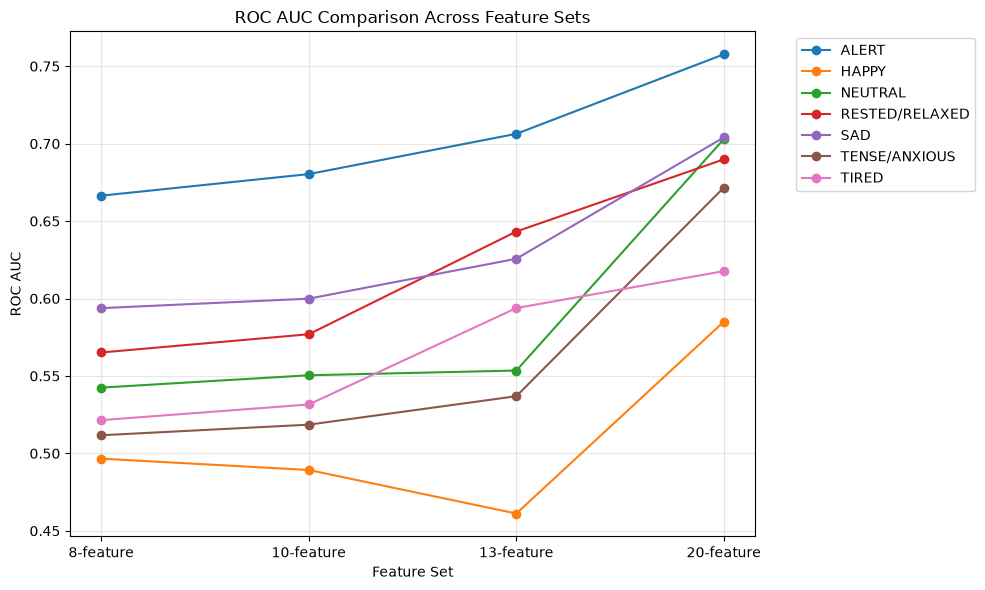

In [ ]:

import matplotlib.pyplot as plt

Featrs = ["8-feature", "10-feature", "13-feature", "20-feature"]

plt.figure(figsize=(10, 6))

for i, mood in enumerate(mood_cols):
    plt.plot(Featrs, A[i, :], marker="o", label=mood)

plt.xlabel("Feature Set")
plt.ylabel("ROC AUC")
plt.title("ROC AUC Comparison Across Feature Sets")
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("../figures/AUC-comparison-across_features.png", dpi=300, bbox_inches="tight")
plt.show()

## Saving the transformed train set (dev_demo.pkl) and the test set(df_test.pkl) and the validation folds

In [29]:

import pickle
from pathlib import Path


output_dir = Path("../procdata_para_thresh/")
output_dir.mkdir(exist_ok=True)

# Save developed and final test datasets
dev_demo.to_pickle(output_dir / "dev_demo.pkl")
df_test.to_pickle(output_dir / "df_test.pkl")


with open(output_dir / "folds.pkl", "wb") as f:
    pickle.dump(folds, f)



## Rolling Window Average - 20 feature - Logistic Regression

In [32]:
window_sizes_to_test = [1, 2, 3, 4, 5, 6, 7 , 8, 9, 10, 11, 12, 13, 14]
all_results = []

numeric_features = baseline_features + [
    "resting_hr",
    "sleep_efficiency"
]

demographic_features = [
    "age", "gender", "bmi_group"
]

historical_moods = [
    "ALERT", "HAPPY", "NEUTRAL",
    "RESTED/RELAXED", "SAD",
    "TENSE/ANXIOUS", "TIRED"
]


for w_size in window_sizes_to_test:
    print(f"Evaluating window size: {w_size} days...")
    
    df_eval = dev_demo.copy()

    # Calculate rolling averages for numeric features
    numeric_rolling = []
    for col in numeric_features:
        roll_col = f"{col}_roll_{w_size}d"
        df_eval[roll_col] = df_eval.groupby("id")[col].transform(
            lambda x: x.rolling(window=w_size, min_periods=1).mean()
        )
        numeric_rolling.append(roll_col)

    # Calculate rolling averages for historical moods
    mood_rolling = []
    for col in historical_moods:
        roll_col = f"{col}_roll_{w_size}d"
        df_eval[roll_col] = df_eval.groupby("id")[col].transform(
            lambda x: x.rolling(window=w_size, min_periods=1).mean()
        )
        mood_rolling.append(roll_col)

    for fold_num, (fit_idx, val_idx) in enumerate(folds, start=1):

        fold_fit = df_eval.loc[fit_idx]
        fold_val = df_eval.loc[val_idx]

        for target in next_cols:

            y_fit = fold_fit[target].astype(int)
            y_val = fold_val[target].astype(int)

            if y_fit.nunique() < 2:
                continue

            # 20 Feature Model =  Numeric rolling mean (10 features) + Mood rolling mean (7 features) + Demographic (3 features)
            curr_features = numeric_rolling + mood_rolling + demographic_features 
            
            transformers = [
                (
                    "num",
                    make_pipeline(SimpleImputer(strategy="median"), StandardScaler()),
                    numeric_rolling
                ),
                (
                    "demo",
                    OneHotEncoder(handle_unknown="ignore"),
                    demographic_features
                ),
                (
                    "mood_history",
                    make_pipeline(SimpleImputer(strategy="median"), StandardScaler()),
                    mood_rolling
                )
            ]

            preprocessor = ColumnTransformer(transformers)

            model = make_pipeline(
                preprocessor,
                LogisticRegression(max_iter=2000, random_state=42)
            )

            model.fit(fold_fit[curr_features], y_fit)
            probabilities = model.predict_proba(fold_val[curr_features])[:, 1]

            all_results.append({
                "Window_Size": w_size,
                "Fold": fold_num,
                "Mood": target,
                "AUC": (roc_auc_score(y_val, probabilities) if y_val.nunique() == 2 else np.nan)
            })

full_results_df = pd.DataFrame(all_results)
agg_df = full_results_df.groupby(["Window_Size", "Mood"])["AUC"].mean().reset_index()

Evaluating window size: 1 days...
Evaluating window size: 2 days...
Evaluating window size: 3 days...
Evaluating window size: 4 days...
Evaluating window size: 5 days...
Evaluating window size: 6 days...
Evaluating window size: 7 days...
Evaluating window size: 8 days...
Evaluating window size: 9 days...
Evaluating window size: 10 days...
Evaluating window size: 11 days...
Evaluating window size: 12 days...
Evaluating window size: 13 days...
Evaluating window size: 14 days...


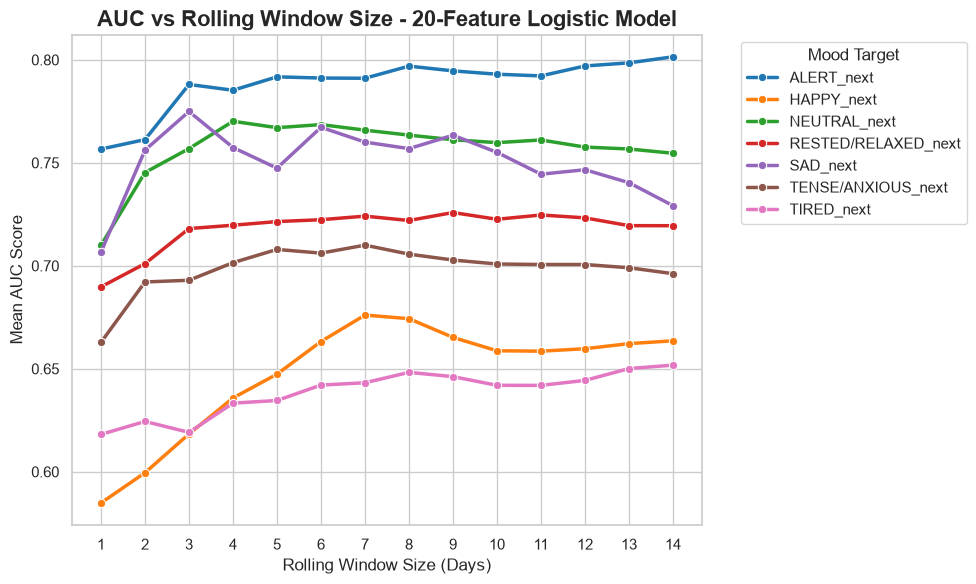

In [33]:
import seaborn as sns

sns.set_theme(style="whitegrid")

plt.figure(figsize=(10, 6))

sns.lineplot(
    data=agg_df,
    x="Window_Size",
    y="AUC",
    hue="Mood",
    marker="o",
    palette="tab10",
    linewidth=2.5
)

plt.title("AUC vs Rolling Window Size - 20-Feature Logistic Model", fontsize=16, fontweight='bold')
plt.xlabel("Rolling Window Size (Days)", fontsize=12)
plt.ylabel("Mean AUC Score", fontsize=12)
plt.xticks(window_sizes_to_test)

plt.legend(title="Mood Target", bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()

plt.show()

## Rolling Window Average - 20 feature - Cross-model comparison

In [34]:

from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import PolynomialFeatures


window_sizes_to_test = [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14]
all_results = []

numeric_features = baseline_features + [
    "resting_hr",
    "sleep_efficiency"
]

demographic_features = [
    "age", "gender", "bmi_group"
]

historical_moods = [
    "ALERT", "HAPPY", "NEUTRAL",
    "RESTED/RELAXED", "SAD",
    "TENSE/ANXIOUS", "TIRED"
]


for w_size in window_sizes_to_test:
    print(f"Evaluating window size: {w_size} days...")
    
    df_eval = dev_demo.copy()

    # Calculate rolling averages for numeric features
    numeric_rolling = []
    for col in numeric_features:
        roll_col = f"{col}_roll_{w_size}d"
        df_eval[roll_col] = df_eval.groupby("id")[col].transform(
            lambda x: x.rolling(window=w_size, min_periods=1).mean()
        )
        numeric_rolling.append(roll_col)

    # Calculate rolling averages for historical moods
    mood_rolling = []
    for col in historical_moods:
        roll_col = f"{col}_roll_{w_size}d"
        df_eval[roll_col] = df_eval.groupby("id")[col].transform(
            lambda x: x.rolling(window=w_size, min_periods=1).mean()
        )
        mood_rolling.append(roll_col)

    for fold_num, (fit_idx, val_idx) in enumerate(folds, start=1):

        fold_fit = df_eval.loc[fit_idx]
        fold_val = df_eval.loc[val_idx]

        for target in next_cols:

            y_fit = fold_fit[target].astype(int)
            y_val = fold_val[target].astype(int)

            if y_fit.nunique() < 2:
                continue

            # 20 Feature Model =  Numeric rolling mean (10 features) + Mood rolling mean (7 features) + Demographic (3 features)
            curr_features = numeric_rolling + mood_rolling + demographic_features 
            
            transformers = [
                (
                    "num",
                    make_pipeline(SimpleImputer(strategy="median"), StandardScaler()),
                    numeric_rolling
                ),
                (
                    "demo",
                    OneHotEncoder(handle_unknown="ignore"),
                    demographic_features
                ),
                (
                    "mood_history",
                    make_pipeline(SimpleImputer(strategy="median"), StandardScaler()),
                    mood_rolling
                )
            ]

            preprocessor = ColumnTransformer(transformers)

            models = [
                ("Standard Logistic",
                make_pipeline(preprocessor,
                LogisticRegression(max_iter=2000, random_state=42))
                ),
                ("Quadratic Logistic",
                make_pipeline(preprocessor, PolynomialFeatures(degree=2, include_bias=False),
                LogisticRegression(max_iter=5000))
                ),
                ("KNN Classifier",
                make_pipeline(preprocessor, KNeighborsClassifier(n_neighbors=10))
                )
            ]

            for model_name, model in models:
                
                model.fit(fold_fit[curr_features], y_fit)
                probabilities = model.predict_proba(fold_val[curr_features])[:, 1]

                all_results.append({
                    "Window_Size": w_size,
                    "Fold": fold_num,
                    "Mood": target,
                    "Model": model_name,
                    "AUC": (roc_auc_score(y_val, probabilities) if y_val.nunique() == 2 else np.nan)
                })

full_results_df = pd.DataFrame(all_results)
agg_df = full_results_df.groupby(["Window_Size", "Model", "Mood"])["AUC"].mean().reset_index()

Evaluating window size: 1 days...
Evaluating window size: 2 days...
Evaluating window size: 3 days...
Evaluating window size: 4 days...
Evaluating window size: 5 days...
Evaluating window size: 6 days...
Evaluating window size: 7 days...
Evaluating window size: 8 days...
Evaluating window size: 9 days...
Evaluating window size: 10 days...
Evaluating window size: 11 days...
Evaluating window size: 12 days...
Evaluating window size: 13 days...
Evaluating window size: 14 days...


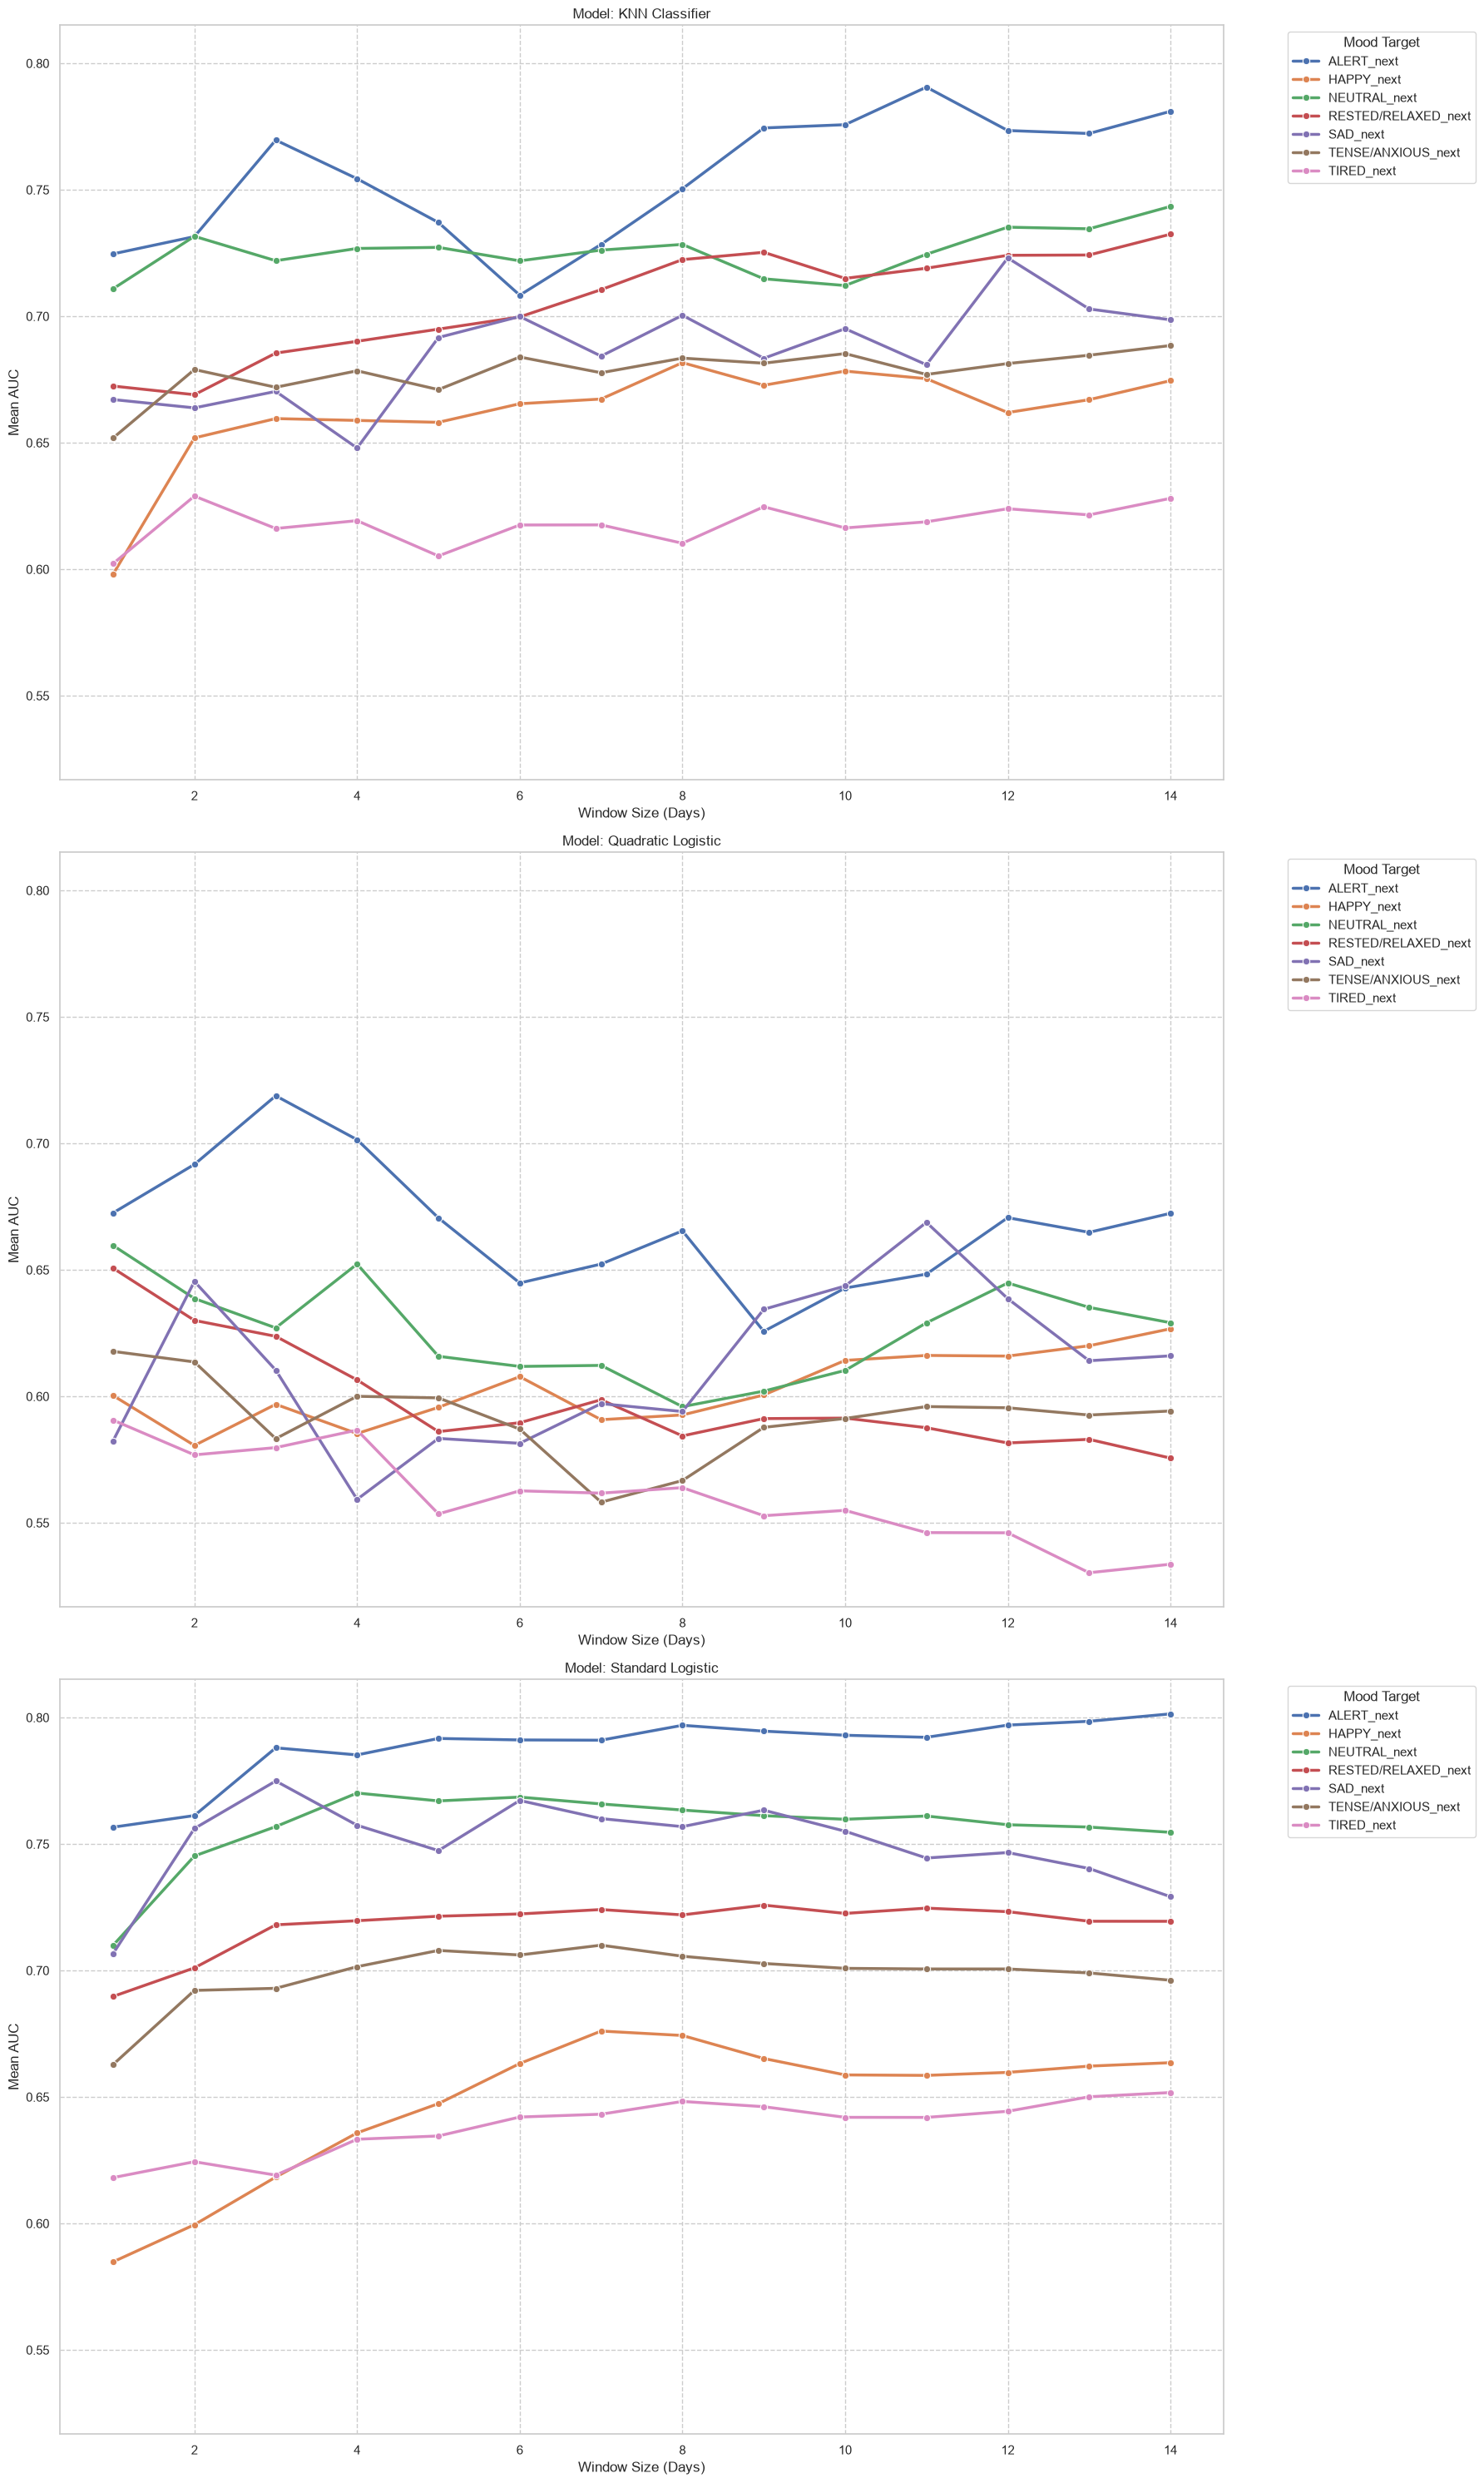

In [35]:
unique_models = agg_df["Model"].unique()

fig, axes = plt.subplots(3, 1, figsize=(18, 30), sharey=True)

for i, model_name in enumerate(unique_models):
    ax = axes[i]
    
    model_data = agg_df[agg_df["Model"] == model_name]
    
    sns.lineplot(
        data=model_data,
        x="Window_Size",
        y="AUC",
        hue="Mood",
        marker="o",
        linewidth=2.5,
        ax=ax
    )
    
    ax.set_title(f"Model: {model_name}")
    ax.set_xlabel("Window Size (Days)")
    ax.set_ylabel("Mean AUC")
        
    ax.grid(True, linestyle="--", alpha=1.0)
    ax.legend(title="Mood Target", bbox_to_anchor=(1.05, 1), loc='upper left')

plt.tight_layout()
plt.show()